In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root
PROJECT_ROOT = Path.cwd().parent

# Raw data folder
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Find CSV files
csv_files = list(RAW_DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV file found in {RAW_DATA_DIR}. "
        "Make sure the PaySim CSV is inside data/raw/."
    )

DATA_PATH = csv_files[0]

print(f"Dataset found: {DATA_PATH.name}")
print(f"Path: {DATA_PATH}")

Dataset found: PS_20174392719_1491204439457_log.csv
Path: d:\Prem\Projects\fraudshield\data\raw\PS_20174392719_1491204439457_log.csv


In [2]:
sample = pd.read_csv(DATA_PATH, nrows=5000)

print("Shape of sample:", sample.shape)
print("\nColumns:")
print(sample.columns.tolist())

sample.head()

Shape of sample: (5000, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            5000 non-null   int64  
 1   type            5000 non-null   str    
 2   amount          5000 non-null   float64
 3   nameOrig        5000 non-null   str    
 4   oldbalanceOrg   5000 non-null   float64
 5   newbalanceOrig  5000 non-null   float64
 6   nameDest        5000 non-null   str    
 7   oldbalanceDest  5000 non-null   float64
 8   newbalanceDest  5000 non-null   float64
 9   isFraud         5000 non-null   int64  
 10  isFlaggedFraud  5000 non-null   int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 429.8 KB


In [4]:
sample.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,5000.0,NaN,NaN,NaN,1.8914,1.175705,1.0,1.0,1.0,3.0,5.0
type,5000,5,PAYMENT,2587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,5000.0,NaN,NaN,NaN,101517.56378,300962.329334,6.42,3734.9225,10958.55,108604.585,10000000.0
nameOrig,5000,5000,C1231006815,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,5000.0,NaN,NaN,NaN,1042543.400612,2301985.714553,0.0,572.25,26550.555,295718.28,12930418.44
newbalanceOrig,5000.0,NaN,NaN,NaN,1064337.794818,2343680.002691,0.0,0.0,18141.855,300320.69,13010502.78
nameDest,5000,3006,C985934102,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,5000.0,NaN,NaN,NaN,918153.634206,2541758.977139,0.0,0.0,0.0,363847.48,19516116.38
newbalanceDest,5000.0,NaN,NaN,NaN,1064912.46547,2921891.971154,0.0,0.0,0.0,270110.78,19169204.93
isFraud,5000.0,NaN,NaN,NaN,0.008,0.089093,0.0,0.0,0.0,0.0,1.0


In [5]:
CHUNK_SIZE = 100_000

total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE):
    total_rows += len(chunk)

print(f"Total transactions: {total_rows:,}")

Total transactions: 6,362,620


In [6]:
fraud_counts = {0: 0, 1: 0}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["isFraud"],
    chunksize=CHUNK_SIZE
):
    counts = chunk["isFraud"].value_counts()

    fraud_counts[0] += counts.get(0, 0)
    fraud_counts[1] += counts.get(1, 0)

total = fraud_counts[0] + fraud_counts[1]

print(f"Legitimate transactions: {fraud_counts[0]:,}")
print(f"Fraudulent transactions: {fraud_counts[1]:,}")
print(f"Total transactions:       {total:,}")

fraud_rate = fraud_counts[1] / total * 100

print(f"\nFraud rate: {fraud_rate:.4f}%")
print(f"Legitimate rate: {100 - fraud_rate:.4f}%")

Legitimate transactions: 6,354,407
Fraudulent transactions: 8,213
Total transactions:       6,362,620

Fraud rate: 0.1291%
Legitimate rate: 99.8709%


In [7]:
transaction_type_counts = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["type"],
    chunksize=CHUNK_SIZE
):
    counts = chunk["type"].value_counts()

    for transaction_type, count in counts.items():
        transaction_type_counts[transaction_type] = (
            transaction_type_counts.get(transaction_type, 0) + count
        )

transaction_type_counts = pd.Series(transaction_type_counts).sort_values(
    ascending=False
)

print(transaction_type_counts)

CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
dtype: int64


In [15]:
fraud_by_type = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["type", "isFraud"],
    chunksize=CHUNK_SIZE
):
    grouped = chunk.groupby("type")["isFraud"].agg(
        total_transactions="count",
        fraud_count="sum"
    )

    for transaction_type, row in grouped.iterrows():
        if transaction_type not in fraud_by_type:
            fraud_by_type[transaction_type] = {
                "total_transactions": 0,
                "fraud_count": 0
            }

        fraud_by_type[transaction_type]["total_transactions"] += int(
            row["total_transactions"]
        )
        fraud_by_type[transaction_type]["fraud_count"] += int(
            row["fraud_count"]
        )

fraud_by_type = pd.DataFrame.from_dict(
    fraud_by_type,
    orient="index"
)

fraud_by_type["fraud_rate"] = (
    fraud_by_type["fraud_count"]
    / fraud_by_type["total_transactions"]
    * 100
)

fraud_by_type.sort_values(
    "fraud_rate",
    ascending=False
)

,total_transactions,fraud_count,fraud_rate
TRANSFER,532909,4097,0.768799
CASH_OUT,2237500,4116,0.183955
CASH_IN,1399284,0,0.000000
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000


In [16]:
balance_pattern_counts = {
    0: {"matches": 0, "total": 0},
    1: {"matches": 0, "total": 0}
}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["amount", "oldbalanceOrg", "isFraud"],
    chunksize=CHUNK_SIZE
):
    chunk["amount_equals_oldbalance"] = np.isclose(
        chunk["amount"],
        chunk["oldbalanceOrg"]
    )

    for fraud_label in [0, 1]:
        subset = chunk[chunk["isFraud"] == fraud_label]

        balance_pattern_counts[fraud_label]["matches"] += int(
            subset["amount_equals_oldbalance"].sum()
        )

        balance_pattern_counts[fraud_label]["total"] += len(subset)

for fraud_label, values in balance_pattern_counts.items():
    percentage = (
        values["matches"] / values["total"] * 100
    )

    label = "Fraud" if fraud_label == 1 else "Legitimate"

    print(
        f"{label}: "
        f"{values['matches']:,} / {values['total']:,} "
        f"({percentage:.4f}%)"
    )

Legitimate: 7 / 6,354,407 (0.0001%)
Fraud: 8,034 / 8,213 (97.8205%)


In [17]:
flagged_stats = {
    "total_flagged": 0,
    "total_fraud": 0,
    "fraud_and_flagged": 0
}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["isFraud", "isFlaggedFraud"],
    chunksize=CHUNK_SIZE
):
    flagged_stats["total_flagged"] += int(
        (chunk["isFlaggedFraud"] == 1).sum()
    )

    flagged_stats["total_fraud"] += int(
        (chunk["isFraud"] == 1).sum()
    )

    flagged_stats["fraud_and_flagged"] += int(
        (
            (chunk["isFraud"] == 1)
            & (chunk["isFlaggedFraud"] == 1)
        ).sum()
    )

print(f"Flagged transactions: {flagged_stats['total_flagged']:,}")
print(f"Total fraud transactions: {flagged_stats['total_fraud']:,}")
print(
    "Fraud transactions caught by existing flag:",
    f"{flagged_stats['fraud_and_flagged']:,}"
)

Flagged transactions: 16
Total fraud transactions: 8,213
Fraud transactions caught by existing flag: 16


In [10]:
time_stats = {
    "min_step": None,
    "max_step": None
}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["step"],
    chunksize=CHUNK_SIZE
):
    chunk_min = chunk["step"].min()
    chunk_max = chunk["step"].max()

    if time_stats["min_step"] is None:
        time_stats["min_step"] = chunk_min
        time_stats["max_step"] = chunk_max
    else:
        time_stats["min_step"] = min(time_stats["min_step"], chunk_min)
        time_stats["max_step"] = max(time_stats["max_step"], chunk_max)

print(time_stats)
print(f"Number of simulated hours: {time_stats['max_step'] - time_stats['min_step'] + 1}")

{'min_step': np.int64(1), 'max_step': np.int64(743)}
Number of simulated hours: 743


In [11]:
missing_counts = None

for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE):
    chunk_missing = chunk.isna().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

print(missing_counts)

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [12]:
sample_duplicate_count = sample.duplicated().sum()

print(f"Duplicate rows in 5,000-row sample: {sample_duplicate_count}")

Duplicate rows in 5,000-row sample: 0


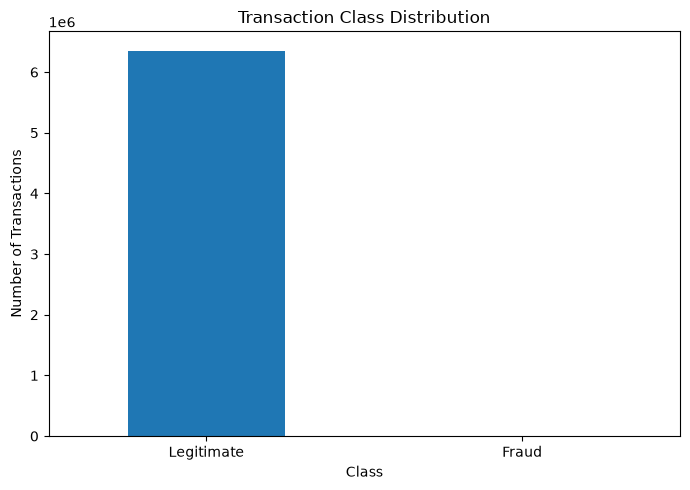

In [13]:
fraud_plot = pd.Series(
    {
        "Legitimate": fraud_counts[0],
        "Fraud": fraud_counts[1],
    }
)

fraud_plot.plot(kind="bar", figsize=(7, 5))

plt.title("Transaction Class Distribution")
plt.ylabel("Number of Transactions")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

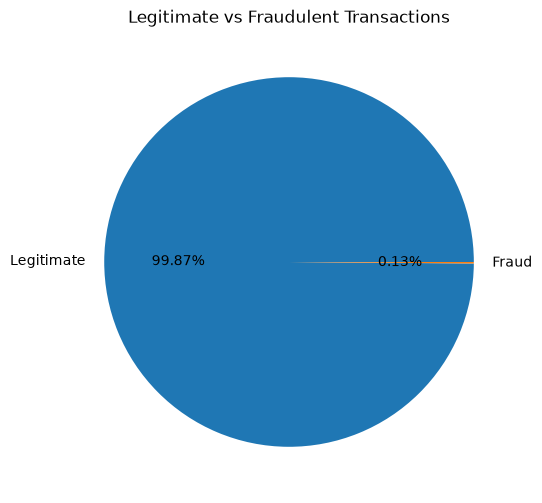

In [14]:
plt.figure(figsize=(6, 6))

plt.pie(
    fraud_plot.values,
    labels=fraud_plot.index,
    autopct="%1.2f%%"
)

plt.title("Legitimate vs Fraudulent Transactions")
plt.show()